# Exploratory Data Analysis — Credit Card Fraud Detection

**What is EDA, and why do it before modeling?**

EDA (Exploratory Data Analysis) means looking carefully at the data *before*
building any model — checking its shape, its quirks, and its patterns, so
that later modeling decisions are based on evidence rather than assumption.
Skipping this step is a common beginner mistake: it's tempting to jump
straight to `model.fit()`, but a model trained on data you don't understand
will make mistakes you won't know how to explain or fix.

By the end of this notebook we'll know: how imbalanced the fraud problem
really is (and why that breaks the usual way of measuring a model), whether
transaction amount or time tells us anything about fraud, and which of the
anonymized features look most informative — all of which will directly
shape how we train the Isolation Forest model in the next phase.


## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Colors picked from a validated, colorblind-safe palette (see project docs).
# Two categories here: "Normal" transactions and "Fraud" transactions.
COLOR_NORMAL = "#2a78d6"   # blue
COLOR_FRAUD  = "#e34948"   # red
COLOR_SEQ    = "#2a78d6"   # single hue for magnitude (correlation chart)
INK_PRIMARY   = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED     = "#898781"
GRIDLINE      = "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRIDLINE,
    "axes.labelcolor": INK_SECONDARY,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "text.color": INK_PRIMARY,
    "grid.color": GRIDLINE,
    "font.size": 11,
    "axes.grid": True,
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

df = pd.read_csv("../data/raw/creditcard.csv")
print(f"Loaded {len(df):,} rows, {df.shape[1]} columns")


Loaded 284,807 rows, 31 columns


## 1. First look at the data

In [2]:
df.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

A quick read of what we're looking at:

- **`Time`** — seconds elapsed since the first transaction in the dataset. Not a
  timestamp, just an offset.
- **`V1` through `V28`** — 28 numerical features that have already been run
  through a technique called **PCA (Principal Component Analysis)** before we
  ever saw the data. In plain terms: the dataset's creators took the *real*
  features (merchant, location, card details, etc. — things that would
  identify real people) and mathematically transformed them into 28
  anonymized numbers that preserve the underlying *patterns* without
  revealing the original, sensitive values. We can't interpret what "high
  `V17`" means in real-world terms, but the model can still use it to learn
  patterns.
- **`Amount`** — the transaction amount, in the original currency, left
  un-anonymized because it's not identifying on its own.
- **`Class`** — the label: `0` = normal transaction, `1` = fraud. This is
  what we're trying to predict (and, since we're building an anomaly
  detector, what we'll use to *evaluate* the model rather than to train it
  directly — more on that in the next notebook).


## 2. The elephant in the room: class imbalance

This is the single most important thing to understand about this dataset
before touching any model.


Class
0    284315
1       492
Name: count, dtype: int64
Fraud rate: 0.1727%


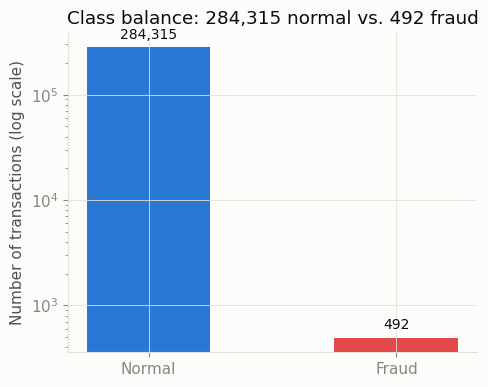

In [4]:
counts = df["Class"].value_counts().sort_index()
fraud_pct = 100 * df["Class"].mean()
print(counts)
print(f"Fraud rate: {fraud_pct:.4f}%")

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(
    ["Normal", "Fraud"],
    [counts[0], counts[1]],
    color=[COLOR_NORMAL, COLOR_FRAUD],
    width=0.5,
)
ax.set_yscale("log")
ax.set_ylabel("Number of transactions (log scale)")
ax.set_title("Class balance: 284,315 normal vs. 492 fraud")
for bar, val in zip(bars, [counts[0], counts[1]]):
    ax.annotate(f"{val:,}", (bar.get_x() + bar.get_width() / 2, val),
                textcoords="offset points", xytext=(0, 6), ha="center",
                fontsize=10, color=INK_PRIMARY)
plt.tight_layout()
plt.show()


**284,315 normal transactions vs. just 492 fraud — a 0.173% fraud rate.**
Note the log scale on that chart; on a normal scale the fraud bar would be
invisible.

Here's why this number matters more than almost anything else in the
project: imagine a model that is simply lazy and predicts "not fraud" for
*every single transaction*, no matter what. That model would be **99.83%
accurate** — and completely useless, since it would catch zero fraud. This
is sometimes called the **accuracy paradox**: with this much imbalance,
accuracy stops being a meaningful way to judge a model.

This is exactly why, in the next notebook, we'll evaluate models using
**precision, recall, and PR-AUC** instead — metrics that specifically look
at how well the model finds the rare fraud cases, rather than how often it's
right overall.


## 3. Does transaction amount differ for fraud vs. normal?

In [5]:
df.groupby("Class")["Amount"].describe()


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


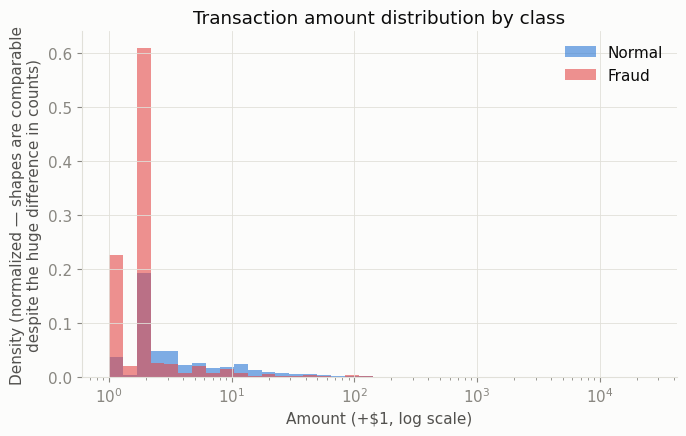

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
bins = np.logspace(0, np.log10(df["Amount"].max() + 1), 40)

ax.hist(df.loc[df.Class == 0, "Amount"] + 1, bins=bins, density=True,
        color=COLOR_NORMAL, alpha=0.6, label="Normal")
ax.hist(df.loc[df.Class == 1, "Amount"] + 1, bins=bins, density=True,
        color=COLOR_FRAUD, alpha=0.6, label="Fraud")
ax.set_xscale("log")
ax.set_xlabel("Amount (+$1, log scale)")
ax.set_ylabel("Density (normalized — shapes are comparable\ndespite the huge difference in counts)")
ax.set_title("Transaction amount distribution by class")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


The two classes look different, but not in the direction you might expect.
Fraud transactions have a **higher mean** ($122.21 vs. $88.29) but a much
**lower median** ($9.25 vs. $22.00). That combination — higher average, lower
typical value — means fraud amounts are usually small, with a handful of
larger outliers pulling the average up. One plausible read (worth treating
as a hypothesis, not a proven fact from this chart alone): small transactions
are sometimes used to quietly test whether a stolen card still works before
attempting something bigger. Either way, the practical takeaway for
modeling is that `Amount` alone is not a reliable fraud signal — the
distributions overlap heavily — but it may still contribute a small amount
of useful signal in combination with the other features.


## 4. Does time of day matter?

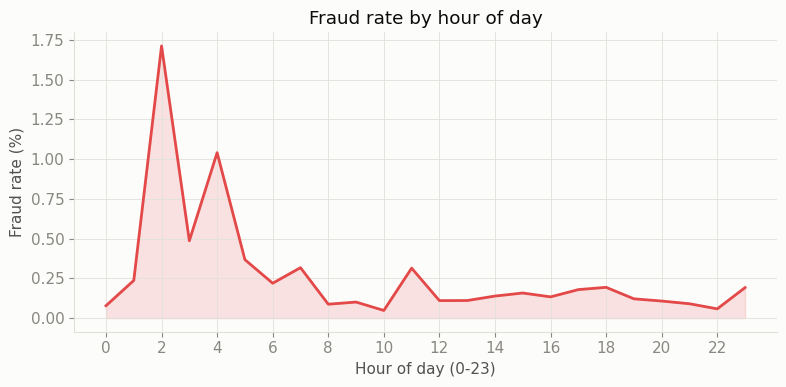

In [7]:
# Time is seconds since the first transaction, spanning ~48 hours total.
# We fold it into a 0-23 "hour of day" so patterns across the two days line up.
df["HourOfDay"] = ((df["Time"] % 86400) / 3600).astype(int)

fraud_rate_by_hour = df.groupby("HourOfDay")["Class"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(fraud_rate_by_hour.index, fraud_rate_by_hour.values,
        color=COLOR_FRAUD, linewidth=2)
ax.fill_between(fraud_rate_by_hour.index, fraud_rate_by_hour.values,
                 color=COLOR_FRAUD, alpha=0.15)
ax.set_xlabel("Hour of day (0-23)")
ax.set_ylabel("Fraud rate (%)")
ax.set_title("Fraud rate by hour of day")
ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()


There's a visible spike in the fraud *rate* in the early hours (around 2-4am)
— worth noting this is the fraud **rate**, not raw count: overall transaction
volume is much lower overnight too, so a handful of fraud cases has an
outsized effect on the percentage during quiet hours. It's a real pattern
worth keeping in mind, but with only 492 fraud cases total spread across 24
hourly buckets, we should be cautious about reading too much precision into
any single hour's number — this is a hint for feature engineering, not a
strong standalone rule.


## 5. Which anonymized features (V1-V28) look most informative?

We can't interpret what `V17` or `V14` *mean* in real-world terms (that's the
point of the PCA anonymization), but we can still measure how strongly each
one is **correlated** with the `Class` label — i.e., how much it tends to
move together with "this was fraud." A feature with a strong correlation is
one the model is likely to lean on heavily.


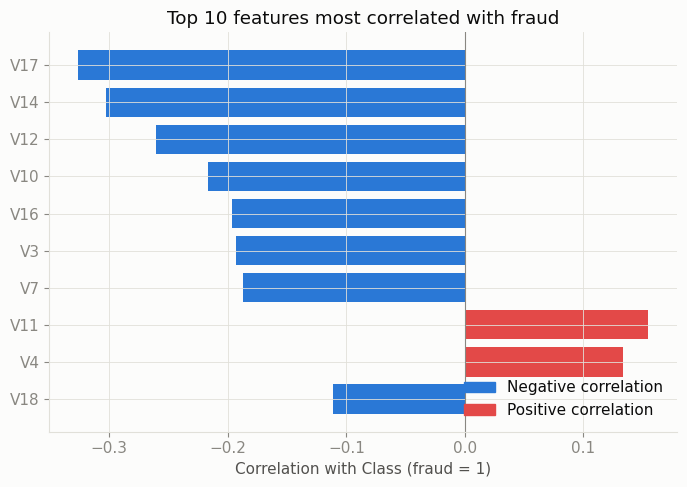

V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
V3    -0.192961
V7    -0.187257
V11    0.154876
V4     0.133447
V18   -0.111485
Name: Class, dtype: float64

In [8]:
v_cols = [c for c in df.columns if c.startswith("V")]
corr_with_class = df[v_cols + ["Class"]].corr()["Class"].drop("Class")
top_corr = corr_with_class.reindex(corr_with_class.abs().sort_values(ascending=False).index).head(10)

fig, ax = plt.subplots(figsize=(7, 5))
# Diverging color: these are signed correlations, so direction (positive vs
# negative) is meaningful, not just magnitude — blue/red is the same
# diverging pair convention used for polarity elsewhere in this project.
bar_colors = [COLOR_FRAUD if v > 0 else COLOR_NORMAL for v in top_corr.values[::-1]]
bars = ax.barh(top_corr.index[::-1], top_corr.values[::-1], color=bar_colors)
ax.axvline(0, color=INK_MUTED, linewidth=0.8)
ax.set_xlabel("Correlation with Class (fraud = 1)")
ax.set_title("Top 10 features most correlated with fraud")
legend_handles = [
    plt.Rectangle((0, 0), 1, 1, color=COLOR_NORMAL, label="Negative correlation"),
    plt.Rectangle((0, 0), 1, 1, color=COLOR_FRAUD, label="Positive correlation"),
]
ax.legend(handles=legend_handles, frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

top_corr


`V17`, `V14`, `V12`, and `V10` stand out as the most correlated with fraud
(all negative — meaning unusually *low* values on these components tend to
coincide with fraud). This won't change how we train the Isolation Forest
(it doesn't need us to hand-pick features), but it's useful context: if the
model's predictions end up leaning heavily on these same four features,
that's a sign it's picking up a real, consistent signal rather than noise —
something we can actually check later.


## 6. Data quality checks

In [9]:
print("Missing values (total across all columns):", df.isnull().sum().sum())
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated rows that are fraud:", df[df.duplicated()]["Class"].sum())


Missing values (total across all columns): 0


Fully duplicated rows: 1081


Duplicated rows that are fraud: 19


Good news: **zero missing values** — one less thing to handle before
modeling. There are **1,081 fully duplicate rows**, which is a known quirk of
this particular dataset (likely a mix of coincidentally identical PCA
vectors and genuine re-logged transactions — we can't tell which from
anonymized data alone). We're not removing them in this notebook, but it's
worth flagging as a decision to make explicitly in the next phase: whether
to de-duplicate before training, and why.


## 7. What this means for the next phase (Isolation Forest)

Pulling the findings above into concrete modeling decisions:

1. **Never evaluate with plain accuracy.** With a 0.173% fraud rate, a
   do-nothing model scores 99.83%. We'll use precision, recall, and PR-AUC
   instead.
2. **`Amount` sits on a very different scale from the `V` columns.**
   `V1`-`V28` come out of PCA roughly standardized (mean ≈ 0, standard
   deviation ≈ 1-2), while `Amount` ranges up to \$25,691 with a standard
   deviation of 250. Whether that matters depends on the model:
   scale-sensitive models, such as the neural-network autoencoder planned for
   later, would let `Amount` dominate for reasons unrelated to fraud, so it
   must be scaled for them. Isolation Forest turns out not to care (tested in
   the next notebook). Raw `Time` is set aside rather than scaled, since it
   only encodes position within this dataset's 48-hour collection window.
3. **`V17`, `V14`, `V12`, `V10` are the strongest individual signals** — a
   useful sanity check to come back to once the model is trained.
4. **The duplicate-row question needs an explicit decision**, not a default.

Next notebook: training and evaluating the Isolation Forest baseline.
